# Figure 3 Supplement 2: Stopping-model fit quality

Does the fitted stopping model reproduce the data it was fit to, on average (A, B)
and choice by choice (C)? Each subject
is simulated `SIM_REPS` times over their own trials (same block, step
statistics and trial count) from their main fit, and the simulated data are
compared with the real data.

OL low-SNR blocks 1–3 (no-penalty, coin-penalty and step-penalty conditions),
as in the other Figure 3 supplements.

- **A — RT distributions**, pooled over subjects; the last bin (15+) collects
  RT ≥ 15.
- **B — accuracy vs. RT** (RT bins with ≥ 20 trials). RT = 1 responses (key
  pressed on the first frame) are anticipations with a random choice in the
  model.
- **C — trial-by-trial choices, per subject.** y: the correlation across that
  subject's trials between the model's probability of a rightward choice
  (`get_choice_probabilities`: given the trial's positions up to the key press
  and its RT) and the actual choice. x: the model's estimate of the fraction of
  that subject's choices that were not driven by the evidence: the mean over
  trials of 1 − (1 − P(guess)) × (1 − lapse rate), with P(guess) the posterior
  probability that the commit was a guess or anticipation
  (`get_commit_type_probabilities`) and the fitted lapse rate. The model
  predicts choices well except to the extent that subjects guess or lapse.
  Subject-blocks with the plateau at a fit limit are left out (counts
  printed).

**Data:** `get_stopping_model_trials('OL', 1–6)` (the trials the model was fit
to; fits are joint over a subject's six blocks), blocks 1–3 shown. Fits: `data/processed/stopping_fits_main.pkl`. All subject-blocks are
included, also those whose plateau sits at a fit limit
(`get_plateau_at_limit`): the model still describes their behavior (random
responding, or committing on any movement), so they belong in a test of fit
quality; their count is printed.

**Conventions:** black = data, blue = model. Replaces the old Figure03S01
(congruence by RT; archived in `notebooks/archive/`).

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import (get_choice_probabilities, get_commit_type_probabilities, get_plateau_at_limit,
                             get_stopping_model_trials, simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 5
SIM_SEED = 11
BLOCKS = ['B1', 'B2', 'B3']   # OL low-SNR blocks, as in the other Figure 3 supplements
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}

# Fit and simulate on all six blocks (the fits are joint across a subject's blocks); show 1-3.
trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits_all = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits_all = fits_all[fits_all.task == 'OL']
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[(fits.task == 'OL') & fits.group.isin(BLOCKS)]
trials = trials[trials.condition.isin(BLOCKS)]
sim = simulate_stopping_data_table(trials, fits_all, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
l_limit = get_plateau_at_limit(fits)
print(f'{len(trials):,} real trials, {len(sim):,} simulated; {fits.subject_index.nunique()} subjects, '
      f'{len(fits)} subject-blocks ({int(l_limit.sum())} with the plateau at a fit limit, included)')

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


14,056 real trials, 70,280 simulated; 60 subjects, 179 subject-blocks (5 with the plateau at a fit limit, included)


In [3]:
MAX_RT = 15
MIN_ACC_TRIALS = 20
rt_ax = np.arange(1, MAX_RT + 1)

def _rt_dist(t):
    return t.RT.clip(upper=MAX_RT).value_counts(normalize=True).reindex(rt_ax, fill_value=0.0)

def _acc_by_rt(t):
    a = t.groupby(t.RT.clip(upper=MAX_RT)).correct.agg(['mean', 'size']).reindex(rt_ax)
    return a['mean'].where(a['size'] >= MIN_ACC_TRIALS * (SIM_REPS if 'rep' in t else 1))

# Largest RT-distribution mismatches, for the record.
mis = pd.DataFrame({b: _rt_dist(sim[sim.condition == b]) - _rt_dist(trials[trials.condition == b]) for b in BLOCKS})
print('model − data P(RT), largest absolute differences:')
print(mis.stack().abs().sort_values(ascending=False).head(6).round(3))

model − data P(RT), largest absolute differences:
RT    
3   B1    0.030
    B3    0.018
2   B1    0.016
3   B2    0.015
6   B3    0.012
    B1    0.010
dtype: float64


In [4]:
# Row C, per subject and block:
# - y: Pearson r across trials between the model's P(right | trajectory up to the press, RT) and the
#   actual choice (0/1): how well the model predicts each choice;
# - x: estimated fraction of uninformed choices, the mean over trials of
#   1 - (1 - P(guess)) * (1 - lapse rate), where P(guess) is the posterior probability that the commit
#   was a guess or anticipation (get_commit_type_probabilities) and the lapse rate is the fitted
#   per-block rate. Wall-censored trials (no defined commit type) are left out of x.
trials['p_right'] = get_choice_probabilities(trials, fits_all, group_col='condition')
trials['p_guess'] = get_commit_type_probabilities(trials, fits_all, group_col='condition')
lapse = fits_all.set_index(['subject_index', 'group']).lapse_rate
trials['uninformed'] = 1 - (1 - trials.p_guess) * (1 - lapse.reindex(pd.MultiIndex.from_arrays(
    [trials.subject_index, trials.condition])).to_numpy())
print(f'wall-censored trials (no P(guess)), left out of x: {int(trials.p_guess.isna().sum())} of {len(trials):,}')

def _r(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.nan if np.std(a) == 0 or np.std(b) == 0 else np.corrcoef(a, b)[0, 1]

rows = []
for (subject, b), g in trials.groupby(['subject_index', 'condition']):
    rows.append({'subject_index': subject, 'condition': b, 'n_trials': len(g),
                 'r_choice': _r(g.p_right, g.choice), 'uninformed': g.uninformed.mean()})
per_subject = pd.DataFrame(rows)
# Subject-blocks with the plateau at a fit limit (no evidence-based stopping) are left out of row C.
at_limit = fits_all.loc[get_plateau_at_limit(fits_all), ['subject_index', 'group']].rename(columns={'group': 'condition'})
l_lim = per_subject.set_index(['subject_index', 'condition']).index.isin(at_limit.set_index(['subject_index', 'condition']).index)
print(f'row C: excluded {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: '
      f'{per_subject.loc[l_lim, ["subject_index", "condition"]].to_dict("records")}')
per_subject = per_subject[~l_lim]
undefined = per_subject[per_subject[['r_choice', 'uninformed']].isna().any(axis=1)]
print(f'{len(per_subject)} subject-blocks; {len(undefined)} with an undefined r (constant choices or predictions), '
      f'not plotted: {undefined[["subject_index", "condition", "n_trials"]].to_dict("records")}')
for b, g in per_subject.dropna().groupby('condition'):
    rho, p = scipy.stats.spearmanr(g.uninformed, g.r_choice)
    print(f'{b}: n = {len(g)}, Spearman rho (uninformed fraction vs. choice r) = {rho:.3f}, p = {p:.2g}')
display(per_subject.groupby('condition')[['r_choice', 'uninformed']].describe(percentiles=[0.1, 0.25, 0.5, 0.75])
        .round(3).T)


wall-censored trials (no P(guess)), left out of x: 114 of 14,056
row C: excluded 5 subject-blocks with the plateau at a fit limit: [{'subject_index': 13, 'condition': 'B3'}, {'subject_index': 44, 'condition': 'B3'}, {'subject_index': 51, 'condition': 'B1'}, {'subject_index': 51, 'condition': 'B2'}, {'subject_index': 59, 'condition': 'B1'}]
174 subject-blocks; 1 with an undefined r (constant choices or predictions), not plotted: [{'subject_index': 51, 'condition': 'B3', 'n_trials': 32}]
B1: n = 58, Spearman rho (uninformed fraction vs. choice r) = -0.875, p = 2.5e-19
B2: n = 59, Spearman rho (uninformed fraction vs. choice r) = -0.819, p = 2.3e-15
B3: n = 56, Spearman rho (uninformed fraction vs. choice r) = -0.821, p = 1e-14


condition             B1      B2      B3
r_choice   count  58.000  59.000  56.000
           mean    0.700   0.853   0.840
           std     0.272   0.213   0.255
           min     0.005  -0.156  -0.114
           10%     0.293   0.681   0.659
           25%     0.511   0.823   0.784
           50%     0.800   0.910   0.942
           75%     0.908   0.986   0.993
           max     1.000   1.000   1.000
uninformed count  58.000  59.000  57.000
           mean    0.378   0.208   0.228
           std     0.333   0.228   0.289
           min     0.000   0.000   0.000
           10%     0.022   0.000   0.000
           25%     0.105   0.041   0.001
           50%     0.252   0.158   0.131
           75%     0.663   0.287   0.291
           max     1.000   1.000   1.000

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


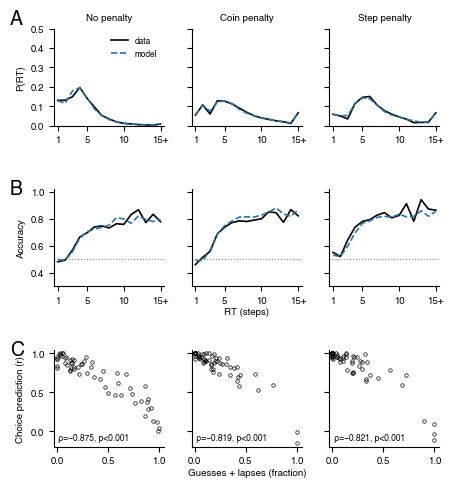

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S02.pdf (+ .png)


In [5]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

fig = plt.figure(figsize=(11 * CM, 12.5 * CM))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.65, wspace=0.25, left=0.1, right=0.99, bottom=0.08, top=0.93)
ax_rt = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_acc = [fig.add_subplot(gs[1, i]) for i in range(3)]
ax_r = [fig.add_subplot(gs[2, i]) for i in range(3)]

for bi, b in enumerate(BLOCKS):
    r, s = trials[trials.condition == b], sim[sim.condition == b]
    ax = ax_rt[bi]
    ax.plot(rt_ax, _rt_dist(r), 'k-', lw=1.2, label='data')
    ax.plot(rt_ax, _rt_dist(s), '--', color=MODEL, lw=1.2, label='model')
    ax.set_title(BLOCK_TITLES[b])
    ax.set_ylim(0, 0.5)
    ax = ax_acc[bi]
    ax.plot(rt_ax, _acc_by_rt(r), 'k-', lw=1.2)
    ax.plot(rt_ax, _acc_by_rt(s), '--', color=MODEL, lw=1.2)
    ax.axhline(0.5, color='0.5', ls=':', lw=0.8)
    ax.set_ylim(0.3, 1.02)
    for a in (ax_rt[bi], ax_acc[bi]):
        a.set_xlim(0.5, MAX_RT + 0.5)
        a.set_xticks([1, 5, 10, 15])
        a.set_xticklabels(['1', '5', '10', '15+'])  # last bin: RT >= 15
        if bi > 0:
            a.set_yticklabels([])
ax_rt[0].set_ylabel('P(RT)')
ax_acc[0].set_ylabel('Accuracy')
ax_rt[0].legend(fontsize=6, frameon=False, loc='upper right')

for bi, b in enumerate(BLOCKS):
    ax = ax_r[bi]
    g = per_subject[per_subject.condition == b].dropna(subset=['r_choice', 'uninformed'])
    ax.plot(g.uninformed, g.r_choice, 'ko', mfc='none', ms=2.5, mew=0.5)
    ax.set_xlim(-0.03, 1.05)
    ax.set_ylim(-0.2, 1.05)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    rho, p = scipy.stats.spearmanr(g.uninformed, g.r_choice)
    ax.text(0.04, 0.05, f'ρ={rho:.3f}, p{"<0.001" if p < 0.001 else f"={p:.3f}"}'.replace('-', '\u2212'),
            transform=ax.transAxes, ha='left', va='bottom', fontsize=6)
    if bi > 0:
        ax.set_yticklabels([])
ax_r[0].set_ylabel('Choice prediction (r)')

# One x label per row, centered under its three panels (same label in every column).
def _row_xlabel(axes, label):
    fig.canvas.draw()
    left, right = axes[0].get_position().x0, axes[-1].get_position().x1
    bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axes)
    fig.text((left + right) / 2, bottom - 0.005, label, ha='center', va='top', fontsize=FS)

_row_xlabel(ax_acc, 'RT (steps)')
_row_xlabel(ax_r, 'Guesses + lapses (fraction)')

for ax in ax_rt + ax_acc + ax_r:
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_rt[0], 'A', dx=-0.4, dy=1.2)
add_panel_label(ax_acc[0], 'B', dx=-0.4, dy=1.1)
add_panel_label(ax_r[0], 'C', dx=-0.4, dy=1.1)

out = FIGURES_DIR / 'Figure03_S02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)